In [3]:

import re
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

from google.colab import files

uploaded = files.upload()


Saving spam_sms.csv to spam_sms.csv


In [5]:

df = pd.read_csv("spam_sms.csv", encoding="latin-1")

print("Dataset shape:", df.shape)
print(df.head())
print("\nColumn names:", df.columns.tolist())


Dataset shape: (5572, 2)
     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Column names: ['v1', 'v2']


In [6]:

# Select the first two columns
df = df.iloc[:, :2].copy()
df.columns = ["label", "message"]

# Remove missing and empty messages
df = df.dropna()
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

# Keep only ham and spam labels
df = df[df["label"].isin(["ham", "spam"])]
df = df[df["message"] != ""]

# Remove duplicate messages
df = df.drop_duplicates(subset=["label", "message"])

# Convert labels into numbers: ham = 0, spam = 1
df["target"] = (df["label"] == "spam").astype(int)

# Convert text to lowercase and remove unnecessary symbols
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s!?$£€%]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["message"] = df["message"].apply(preprocess_text)

print("Cleaned dataset shape:", df.shape)
print(df.head())
print("\nLabel distribution:")
print(df["label"].value_counts())


Cleaned dataset shape: (5158, 3)
  label                                            message  target
0   ham  go until jurong point crazy available only in ...       0
1   ham                            ok lar joking wif u oni       0
2  spam  free entry in 2 a wkly comp to win fa cup fina...       1
3   ham        u dun say so early hor u c already then say       0
4   ham  nah i don t think he goes to usf he lives arou...       0

Label distribution:
label
ham     4516
spam     642
Name: count, dtype: int64


In [7]:

if len(df) < 2000:
    raise ValueError("The cleaned dataset contains fewer than 2,000 messages.")

subset, _ = train_test_split(
    df,
    train_size=2000,
    random_state=42,
    stratify=df["target"]
)

print("Selected messages:", len(subset))
print(subset["label"].value_counts())


Selected messages: 2000
label
ham     1751
spam     249
Name: count, dtype: int64


In [8]:

train_df, test_df = train_test_split(
    subset,
    test_size=0.20,
    random_state=42,
    stratify=subset["target"]
)

print("Training messages:", len(train_df))
print("Testing messages:", len(test_df))


Training messages: 1600
Testing messages: 400


In [9]:

def tokenize(text):
    return re.findall(r"\b\w+\b|[!?$£€%]+", text.lower())

word_counts = Counter(
    word
    for message in train_df["message"]
    for word in tokenize(message)
)

# 0 = padding, 1 = unknown word
vocab = {"<PAD>": 0, "<UNK>": 1}

for word in word_counts:
    vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))
print("Sample tokens:", tokenize(train_df["message"].iloc[0]))


Vocabulary size: 4343
Sample tokens: ['aight', 'i', 'm', 'chillin', 'in', 'a', 'friend', 's', 'room', 'so', 'text', 'me', 'when', 'you', 're', 'on', 'the', 'way']


In [10]:

MAX_LEN = 60

def encode_message(message):
    tokens = tokenize(message)
    sequence = [vocab.get(word, 1) for word in tokens]
    sequence = sequence[:MAX_LEN]
    sequence += [0] * (MAX_LEN - len(sequence))
    return sequence

X_train = torch.tensor(
    np.array([encode_message(m) for m in train_df["message"]]),
    dtype=torch.long
)

X_test = torch.tensor(
    np.array([encode_message(m) for m in test_df["message"]]),
    dtype=torch.long
)

y_train = torch.tensor(
    train_df["target"].to_numpy(),
    dtype=torch.float32
)

y_test = test_df["target"].to_numpy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Example padded sequence:", X_train[0])


X_train shape: torch.Size([1600, 60])
X_test shape: torch.Size([400, 60])
Example padded sequence: tensor([ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0])


In [11]:

class SpamLSTM(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, 64, padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=64,
            batch_first=True
        )

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()
        embedded = self.embedding(x)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)
        output = self.dropout(hidden[-1])

        return self.fc(output).squeeze(1)


model = SpamLSTM(len(vocab))

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)


SpamLSTM(
  (embedding): Embedding(4343, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [12]:

EPOCHS = 8
BATCH_SIZE = 64

for epoch in range(EPOCHS):
    model.train()
    indices = torch.randperm(len(X_train))
    total_loss = 0

    for batch in indices.split(BATCH_SIZE):
        optimizer.zero_grad()

        outputs = model(X_train[batch])
        loss = criterion(outputs, y_train[batch])

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(indices.split(BATCH_SIZE))

    print(
        f"Epoch {epoch + 1}/{EPOCHS} - "
        f"Loss: {average_loss:.4f}"
    )

print("Training completed!")


Epoch 1/8 - Loss: 0.5754
Epoch 2/8 - Loss: 0.3896
Epoch 3/8 - Loss: 0.2933
Epoch 4/8 - Loss: 0.2107
Epoch 5/8 - Loss: 0.1556
Epoch 6/8 - Loss: 0.1146
Epoch 7/8 - Loss: 0.0837
Epoch 8/8 - Loss: 0.0570
Training completed!


In [13]:

model.eval()

with torch.no_grad():
    probabilities = torch.sigmoid(model(X_test)).numpy()

predictions = (probabilities >= 0.5).astype(int)

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(
    y_test, predictions, zero_division=0
)
recall = recall_score(
    y_test, predictions, zero_division=0
)
f1 = f1_score(
    y_test, predictions, zero_division=0
)

print("MODEL EVALUATION RESULTS")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))


MODEL EVALUATION RESULTS
Accuracy : 0.9675
Precision: 0.9302
Recall   : 0.8000
F1-score : 0.8602

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      0.99      0.98       350
        Spam       0.93      0.80      0.86        50

    accuracy                           0.97       400
   macro avg       0.95      0.90      0.92       400
weighted avg       0.97      0.97      0.97       400



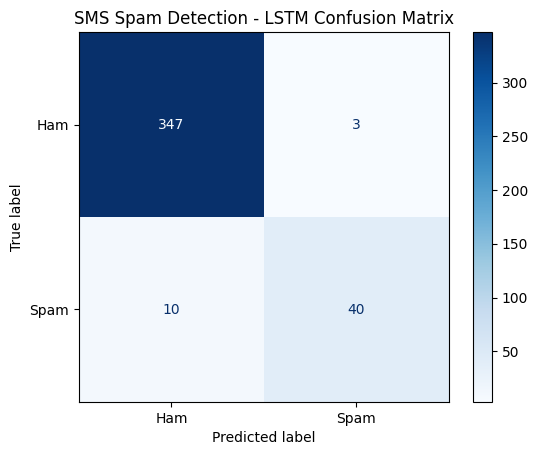

In [15]:

cm = confusion_matrix(
    y_test,
    predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("SMS Spam Detection - LSTM Confusion Matrix")
plt.show()


In [25]:

def predict_sms(message):
    processed_message = preprocess_text(message)

    sequence = torch.tensor(
        [encode_message(processed_message)],
        dtype=torch.long
    )

    model.eval()

    with torch.no_grad():
        probability = torch.sigmoid(model(sequence)).item()

    prediction = "SPAM" if probability >= 0.5 else "HAM"

    print("\nSMS:", message)
    print("Prediction:", prediction)
    print(f"Spam probability: {probability:.2%}")


predict_sms(
    "Congratulations! You won a free prize. Call now to claim."
)

predict_sms(
    "Hi, are we meeting at 6 pm today?"
)



SMS: Congratulations! You won a free prize. Call now to claim.
Prediction: SPAM
Spam probability: 87.19%

SMS: Hi, are we meeting at 6 pm today?
Prediction: HAM
Spam probability: 0.10%


In [21]:

print("CONCLUSION")
print("The LSTM model was trained to classify SMS messages.")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print("The model predicts whether a message is Spam or Ham.")


CONCLUSION
The LSTM model was trained to classify SMS messages.
Test Accuracy: 96.75%
The model predicts whether a message is Spam or Ham.
